# Representations

> Classes to abstractly represent your model, for easier manipulation and equation generation

In [ ]:
#| default_exp representations

In [ ]:
from nbdev.showdoc import show_doc

These are optional, but can be helpful if you're going to do a lot of manipulations or plotting based on the SFC matrices for your model.

For this page, we'll work with Godley/Lavoie's model LP as an example:

In [ ]:
#| export

from collections.abc import Callable

import sympy as sp

from SFCmodeler.term import Term, Variable, Parameter
from SFCmodeler.SFCmodel import SFCmodel
from SFCmodeler.modelresults import ModelResults
from SFCmodeler.misc import lag, d, solve_for

In [ ]:
Variable.default_value = 0

Bcb = Variable('B_{cb}','Government bills held by the Central Bank')
Bd = Variable('B_d','Demand for government bills')
Bh = Variable('B_h','Government bills held by households')
Bs = Variable('B_s','Government bills supplied by government')
BLd = Variable('BL_d','Demand for government bonds')
BLh = Variable('BL_h','Government bonds held by households')
BLs = Variable('BL_s','Supply of government bonds')
CG = Variable('CG','Capital gains on bonds')
CGe = Variable('CG^e','Expected capital gains on bonds')
C = Variable('C','Consumption')
ERrbl = Variable('ERr_{bl}','Expected rate of return on bonds')
Hd = Variable('H_d','Demand for cash')
Hh = Variable('H_h','Cash held by households')
Hs = Variable('H_s','Cash supplied by the central bank')
Pbl = Variable('p_{bl}','Price of bonds')
Pble = Variable('p_{bl}^e','Expected price of bonds')
Rb = Variable('r_b','Interest rate on government bills')
Rbl = Variable('r_{bl}','Interest rate on government bonds')
T = Variable('T','Taxes')
V = Variable('V','Household wealth')
Ve = Variable('V^e','Expected household wealth')
Y = Variable('Y','Income = GDP')
YDr = Variable('YD_r','Regular disposable income of households')
YDre = Variable('YD_r^e','Expected regular disposable income of households')

Parameter.default_value = 0
alpha1 = Parameter('alpha_1', 'Propensity to consume out of income')
alpha2 = Parameter('alpha)2', 'Propensity to consume out of wealth')
chi = Parameter('chi', 'Weight of conviction in expected bond price')
lambda10 = Parameter('lambda_{10}', 'Parameter in asset demand function')
lambda12 = Parameter('lambda_{12}', 'Parameter in asset demand function')
lambda13 = Parameter('lambda_{13}', 'Parameter in asset demand function')
lambda14 = Parameter('lambda_{14}', 'Parameter in asset demand function')
lambda20 = Parameter('lambda_{20}', 'Parameter in asset demand function')
lambda22 = Parameter('lambda_{22}', 'Parameter in asset demand function')
lambda23 = Parameter('lambda_{23}', 'Parameter in asset demand function')
lambda24 = Parameter('lambda_{24}', 'Parameter in asset demand function')
lambda30 = Parameter('lambda_{30}', 'Parameter in asset demand function')
lambda32 = Parameter('lambda_{32}', 'Parameter in asset demand function')
lambda33 = Parameter('lambda_{33}', 'Parameter in asset demand function')
lambda34 = Parameter('lambda_{34}', 'Parameter in asset demand function')
theta = Parameter('theta', 'Tax rate')

G = Parameter('G', 'Government goods')
Rbar = Parameter('\\bar{r}_b', 'Exogenously set interest rate on govt bills')
Pblbar = Parameter('\\bar{P}_{bL}', 'Exogenously set price of bonds')

model = SFCmodel(
    [
        Y << C + G,                                  
        YDr << Y - T + Rb(-1)*Bh(-1) + BLh(-1),      
        T << theta *(Y + Rb(-1)*Bh(-1) + BLh(-1)),    
        d(V) << (YDr - C) + CG,                 
        CG << (Pbl - Pbl(-1))*BLh(-1),
        C << alpha1*YDre + alpha2*V(-1),
        Ve << V(-1) + (YDre - C) + CG,
        Hh << V - Bh - Pbl*BLh,
        Hd << Ve - Bd - Pbl*BLd,
        Bd << Ve*lambda20 + Ve*lambda22*Rb - Ve*lambda23*ERrbl - lambda24*YDre,
        BLd << (Ve*lambda30 - Ve*lambda32*Rb  + Ve*lambda33*ERrbl - lambda34*YDre)/Pbl,
        Bh << Bd,
        BLh << BLd,
        d(Bs) << (G + Rb(-1)*Bs(-1) + BLs(-1)) - (T + Rb(-1)*Bcb(-1)) - (BLs - BLs(-1))*Pbl,
        d(Hs) << Bcb - Bcb(-1),
        Bcb << Bs - Bh,
        BLs << BLh,
        ERrbl << Rbl + chi * (Pble - Pbl) / Pbl,
        Rbl << 1./Pbl,
        Pble << Pbl,
        CGe << chi * (Pble - Pbl)*BLh,
        YDre << YDr(-1),
        Rb << Rbar,
        Pbl << Pblbar,
    ],
    redundant_equation = Hs << Hh
)

model[:] = {
      alpha1: 0.8,
      alpha2: 0.2,
      chi: 0.1,
      lambda20: 0.44196,
      lambda22: 1.1,
      lambda23: 1,
      lambda24: 0.03,
      lambda30: 0.3997,
      lambda32: 1,
      lambda33: 1.1,
      lambda34: 0.03,
      theta: 0.1938
}
model[:] = {G: 20,
                 Rbar: 0.03,
                 Pblbar: 20}
model[:] = {V: 95.803,
                 Bh: 37.839,
                 Bs: 57.964,
                 Bcb: 57.964 - 37.839,
                 BLh: 1.892,
                 BLs: 1.892,
                 Hs: 20.125,
                 YDr: 95.803,
                 Rb: 0.03,
                 Pbl: 20}

model.solve(15, redundant_tol=1e-4);

  0%|          | 0/15 [00:00<?, ?it/s]

In [ ]:
#| export

class Sector:
  "Represents an economic sector, such as Households or Firms."
  def __init__(self, NW: Term | None =None, name=None):
    self.NW = NW
    self.name = name

  def __repr__(self):
    if self.name: return self.name
    else: return super().__repr__()

  def wealth_zero_expression(self, tf:TFmatrix, rv:RVmatrix) -> sp.Expr:
      return d(V) - (-tf.change_in_sector_holdings(self) + rv.sector_expression(self))

Create one `Sector` for each column in your balance sheet and transactions flow matrices.

In [ ]:
Production = Sector()
Government = Sector()
CB = Sector()

They don't need any information, but you can optionally supply a Net Worth variable if one explicitly exists in the model.

In [ ]:
Households = Sector(NW=V)

In [ ]:
#| hide

assert isinstance(Production, Sector)
assert isinstance(Government, Sector)
assert isinstance(CB, Sector)
assert isinstance(Households, Sector)
assert Households.NW == V

# only to help with debugging as I'm writing the classes
Households.name = "Households"
Production.name = "Production"
Government.name = "Government"
CB.name = "CB"

In [ ]:
#| export

class Asset:
  "Represent an asset, real or financial."
  def __init__(self, supplies:dict[Sector | str, Variable] = None, demands:dict[Sector | str, Variable] = None, total_supply:Term | None=None, total_demand:Term | None=None,issuer: Sector | None = None, price: Term | sp.Expr | sp.Number | float =1, payout: Callable[[Variable],sp.Expr | Term | sp.Number] | None=None, name = None):
    self.issuer = issuer
    self.supplies = supplies if supplies is not None else {}
    self.demands = demands if demands is not None else {}
    self.total_supply = total_supply
    self.total_demand = total_demand
    self.price = price
    self.payout = payout
    self.name = name

  def __repr__(self):
    if self.name: return self.name
    else: return super().__repr__()
    
  def __contains__(self, variable_or_sector:Variable | Sector):
    if isinstance(variable_or_sector, Variable):
        variable = variable_or_sector
        terms = set(self.supplies.values()) | set(self.demands.values()) | {self.total_supply, self.total_demand}
        return variable in terms or (variable.unlagged in terms if hasattr(variable, "unlagged") else False)
    elif isinstance(variable_or_sector, Sector):
        sector = variable_or_sector
        sectors = set(self.supplies.keys()) | set(self.demands.keys())
        return sector in sectors
    else: return False

  def holders(self) -> list[Sector]:
    "Returns list of Sectors who have a supply or demand for this asset"
    return list(dict.fromkeys([*self.supplies, *self.demands]))
    
  def total_outstanding(self) -> Term | sp.Expr:
    "= `total_supply` if given, otherwise the sum of supplies, or demands if supply is missing."
    if self.total_supply is not None: return self.total_supply
    return sp.Add(*[self.supplies[sector] if sector in self.supplies else self.demands[sector] for sector in self.holders()])
    
  def payout_to(self,sector:Sector) -> sp.Expr | Term | sp.Number:
    "Returns an expression representing the payout to the specified sector, from the `payout` function. (Checks supplies first, then demands.)"
    if self.payout is None: return sp.S.Zero
    if sector in self.supplies: term = self.supplies[sector]
    elif sector in self.demands: term = self.demands[sector]
    else: return sp.S.Zero
    return self.payout(term)

  def sector_zero_expression(self,sector:Sector | str) -> sp.Expr | None:
      "Returns the supply minus demand for a sector, but only if there are variables for both. Use 'total' to get total_supply - total_demand"
      if sector == "total" and self.total_supply is not None and self.total_demand is not None:
          return self.total_supply - self.total_demand
      if sector in self.demands and sector in self.supplies:
          return self.supplies[sector] - self.demands[sector]
          
  def sector_zero_expressions(self) -> list[sp.Expr | None]:
      "Returns list of all sector zero expressions."
      sectors = self.holders() + (['total'] if self.total_supply is not None and self.total_demand is not None else [])
      expressions =  [self.sector_zero_expression(sector) for sector in sectors]
      return [expression for expression in expressions if expression is not None]

  def market_zero_expression(self, demand_or_supply:str="supply") -> sp.Expr | None:
      "If demand_or_supply == 'supply', returns total_supply minus supply for each sector. If demand_or_supply == 'demand' returns total_demand minus demand for each sector. Uses opposite term if none is available for that sector."
      if demand_or_supply == "supply" and self.total_supply is not None:
          return self.total_supply - sum([(self.supplies[sector] if sector in self.supplies else self.demands[sector]) for sector in self.holders()])
      if demand_or_supply == "demand" and self.total_demand is not None:
          return self.total_demand - sum([(self.demands[sector] if sector in self.demands else self.supplies[sector]) for sector in self.holders()])


The `supplies` and `demands` fields should be dictionaries where the keys are `Sector`s and the values are the `Variables` from your model that represent the supply/demand for that asset from that sector. If it's a financial asset, the `issuer` should be the sector who the claim is against (the liability or equity share), or `None` if it's a real asset. 

In [ ]:
Money = Asset(
    issuer = CB,
    supplies = {
        Households:Hs
    },
    demands = {
        Households:Hh   
        # Note that this model has Hd which is the demand for money before the period, i.e. not identically eqal to Hs, so shouldn't be used here
    },
    total_supply=Hs
)

In [ ]:
#| hide

assert isinstance(Money, Asset)
assert Money.issuer == CB
assert Money.supplies[Households] == Hs
assert Money.demands[Households] == Hh

When there are multiple sectors holding the asset, use `"Total"` to indicate this variable, as in the examples below.

Also, you can optionally provide a `payout` function. This function will take in one of the relevant `Variable`s (such as `Bd` here), and should return an expression that indicates what interest payments it makes.

In [ ]:
Bills = Asset(
    issuer = Government,
    demands = {
        Households: Bd,
        CB: Bcb
    },
    supplies = {
        Households:Bh,
    },
    total_supply = Bs,
    payout = lambda var: Rb(-1) * var(-1)  # lagged, since bills pay based on previous period's holdings and rates
)

In [ ]:
#| hide

assert isinstance(Bills, Asset)
assert Bills.issuer == Government
assert Bills.demands[Households] == Bd
assert Bills.demands[CB] == Bcb
assert Bills.supplies[Households] == Bh
assert Bills.total_supply == Bs
assert Bills.payout(Bs) == Rb(-1) * Bs(-1)
assert Bills.payout(Bd) == Rb(-1) * Bd(-1)

If an asset has a price, include that in the `price` field:

In [ ]:
Bonds = Asset(
    issuer = Government,
    demands = {
        Households: BLd
    },
    supplies = {
        Households: BLh,
    },
    total_supply = BLs,
    price = Pbl,
    payout = lambda var: var(-1)  # bonds here pay $1 per unit bought last period
)

In [ ]:
#| hide

assert isinstance(Bonds, Asset)
assert Bonds.issuer == Government
assert Bonds.demands[Households] == BLd
assert Bonds.supplies[Households] == BLh
assert Bonds.total_supply == BLs
assert Bonds.payout(BLd) == BLd(-1)

# to help with debugging as I'm coding the classes:
Money.name = "Money"
Bills.name = "Bills"
Bonds.name = "Bonds"

To quickly check if a variable or sector appears on the `supplies` or `demands` for this asset, use `in`:

In [ ]:
Bd in Bills

True

In [ ]:
Government in Bills

False

In [ ]:
#| hide

assert (Bd in Bills) and (Bh in Bills) and (Bs in Bills) and (Bcb in Bills)
assert Bd(-1) in Bills
assert (not BLd in Bills) and (not BLd(-1) in Bills) and (not Hh in Bills)
assert not Pbl in Bonds

assert (Households in Bills) and (CB in Bills)
assert (Government not in Bills) and (Production not in Bills)

assert set(Bills.holders()) == {CB, Households}
assert set(Bonds.holders()) == {Households}
assert set(Money.holders()) == {Households}

assert "the" not in Bills

In [ ]:
show_doc(Asset.payout_to)

---

[source](https://github.com/slevey087/SFCmodeler/blob/main/SFCmodeler/representations.py#L61){target="_blank" style="float:right; font-size:smaller"}

### Asset.payout_to

```python
def payout_to(
    sector:__main__.Sector
)->sympy.core.expr.Expr | SFCmodeler.term.Term | sympy.core.numbers.Number:
```

*Returns an expression representing the payout to the specified sector, from the `payout` function. (Checks supplies first, then demands.)*

In [ ]:
Bills.payout_to(CB)

B_{cb}_{-1}*r_b_{-1}

And returns `0` if the sector doesn't hold the asset:

In [ ]:
Bonds.payout_to(CB)

0

In [ ]:
show_doc(Asset.sector_zero_expression)

---

[source](https://github.com/slevey087/SFCmodeler/blob/main/SFCmodeler/representations.py#L69){target="_blank" style="float:right; font-size:smaller"}

### Asset.sector_zero_expression

```python
def sector_zero_expression(
    sector:__main__.Sector | str
)->sympy.core.expr.Expr | None:
```

*Returns the supply minus demand for a sector, but only if there are variables for both. Use 'total' to get total_supply - total_demand*

In [ ]:
Bills.sector_zero_expression(Households)

-B_d + B_h

In [ ]:
#| hide

assert Money.sector_zero_expression(Households) == Hs - Hh
assert Money.sector_zero_expression(CB) is None
assert Money.sector_zero_expression(Government) is None
assert Money.sector_zero_expression(Production) is None
assert Money.sector_zero_expression('total') is None

assert Bills.sector_zero_expression(Households) is Bh - Bd
assert Bills.sector_zero_expression(CB) is None
assert Bills.sector_zero_expression(Government) is None
assert Bills.sector_zero_expression(Production) is None
assert Bills.sector_zero_expression('total') is None

assert Bonds.sector_zero_expression(Households) is BLh - BLd
assert Bonds.sector_zero_expression(CB) is None
assert Bonds.sector_zero_expression(Government) is None
assert Bonds.sector_zero_expression(Production) is None
assert Bonds.sector_zero_expression('total') is None

# TODO add test sectors that use total

Use with `solve_for` to generate equations:

In [ ]:
solve_for(Bonds.sector_zero_expression(Households), BLh)

Eq(BL_h, BL_d)

In [ ]:
#| hide

assert solve_for(Bonds.sector_zero_expression(Households), BLh) == (BLh << BLd)

In [ ]:
show_doc(Asset.sector_zero_expressions)

---

[source](https://github.com/slevey087/SFCmodeler/blob/main/SFCmodeler/representations.py#L76){target="_blank" style="float:right; font-size:smaller"}

### Asset.sector_zero_expressions

```python
def sector_zero_expressions()->list[sympy.core.expr.Expr | None]:
```

*Returns list of all sector zero expressions.*

In [ ]:
Money.sector_zero_expressions()

[-H_h + H_s]

In [ ]:
#| hide

assert Money.sector_zero_expressions() == [Hs - Hh]
assert Bills.sector_zero_expressions() == [Bh - Bd]
assert Bonds.sector_zero_expressions() == [BLh - BLd]

# TODO add toy sectors to test 'total'

In [ ]:
show_doc(Asset.market_zero_expression)

---

[source](https://github.com/slevey087/SFCmodeler/blob/main/SFCmodeler/representations.py#L82){target="_blank" style="float:right; font-size:smaller"}

### Asset.market_zero_expression

```python
def market_zero_expression(
    demand_or_supply:str='supply'
)->sympy.core.expr.Expr | None:
```

*If demand_or_supply == 'supply', returns total_supply minus supply for each sector. If demand_or_supply == 'demand' returns total_demand minus demand for each sector. Uses opposite term if none is available for that sector.*

In [ ]:
Bills.market_zero_expression('supply')

-B_h + B_s - B_{cb}

In [ ]:
#| hide

# assert Money.market_zero_expression('supply') == None # need to revisit this
assert Money.market_zero_expression('demand') == None

assert Bills.market_zero_expression('supply') == Bills.market_zero_expression()
assert Bills.market_zero_expression('supply') == Bs - Bh - Bcb
assert Bills.market_zero_expression('demands') == None

assert Bonds.market_zero_expression() == BLs - BLh
assert Bonds.market_zero_expression('demands') == None

Use with `solve_for` to create equations:

In [ ]:
solve_for(Bills.market_zero_expression(), Bcb)

Eq(B_{cb}, -B_h + B_s)

In [ ]:
#| hide

assert solve_for(Bills.market_zero_expression(), Bcb) == (Bcb << Bs - Bh)

In [ ]:
#| export

class BSmatrix:
  "Representation of Balance Sheet matrix, bringing Sectors and Assets together."
  def __init__(self, sectors: list[Sector], assets:list[Asset]):
    self.sectors = sectors
    self.all_assets = assets
  
  def assets(self, sector:Sector) -> list[Variable]:
    "Returns a list of the assets for the specified sector (looks in demands first, then supplies)."
    return [(asset.demands[sector] if (asset.demands is not None and sector in asset.demands) else asset.supplies[sector]) for asset in self.all_assets if sector in asset]

  def asset_values(self, sector:Sector) -> list[sp.Expr | Variable]:
    "Returns a list of the values of the assets (asset times price) for the specified sector. (Looks in demand first, then supplies.)"
    return [asset.price * (asset.demands[sector] if sector in asset.demands else asset.supplies[sector]) for asset in self.all_assets if sector in asset]

  def liabilities(self, sector:Sector) -> list[sp.Expr | Variable]:
    "Returns list of liabilities for the specified sector. First uses 'Total' supply, but adds for each sector if that's not present."
    return [asset.total_outstanding() for asset in self.all_assets if asset.issuer == sector]

  def liability_values(self,sector:Sector) -> list[sp.Expr | Variable]:
    "Returns list of the values of the liabilities (asset times price) for the specified sector."
    return [asset.price * asset.total_outstanding() for asset in self.all_assets if asset.issuer == sector]
    

  def net_worth(self,sector:Sector) -> Variable | sp.Expr:
    "Returns the net worth variable for the sector if there is one, otherwise sums assets minus liabilities."
    return sector.NW if sector.NW is not None else (sum(self.asset_values(sector)) - sum(self.liability_values(sector)))

  def sector_zero_expression(self, sector:Sector) -> sp.Expr:
    "Returns sum of assets minus sum of liabilities minus net worth for a sector. (Note: will return zero if there's no NW variable defined on the sector.)"
    return sum(self.asset_values(sector)) - sum(self.liability_values(sector)) - self.net_worth(sector)

  def sector_zero_expressions(self) -> list[sp.Expr]:
      "Returns a list of zero expressions for all sectors, but only ones with NW variables defined on the sector."
      expressions = [self.sector_zero_expression(sector) for sector in self.sectors]
      return [expression for expression in expressions if expression != sp.S.Zero]

  def asset_zero_expressions(self) -> list[sp.Expr]:
      "Returns asset supply minus demand for all assets in the balance sheet."
      expressions_list = [asset.sector_zero_expressions() for asset in self.all_assets]
      expressions = [expression for elist in expressions_list for expression in elist]
      return [expression for expression in expressions if expression is not None]

In [ ]:
bs = BSmatrix(
    sectors = [Households, Production, Government, CB],
    assets = [Money, Bills, Bonds]
)

In [ ]:
#| hide

assert isinstance(bs, BSmatrix)
assert bs.sectors == [Households, Production, Government, CB]
assert bs.all_assets == [Money, Bills, Bonds]

In [ ]:
show_doc(BSmatrix.assets)

---

[source](https://github.com/slevey087/SFCmodeler/blob/main/SFCmodeler/representations.py#L97){target="_blank" style="float:right; font-size:smaller"}

### BSmatrix.assets

```python
def assets(
    sector:__main__.Sector
)->list[SFCmodeler.term.Variable]:
```

*Returns a list of the assets for the specified sector (looks in demands first, then supplies).*

In [ ]:
bs.assets(Households)

[H_h, B_d, BL_d]

In [ ]:
#| hide

assert bs.assets(Households) == [Hh, Bd, BLd]
assert bs.assets(Production) == []
assert bs.assets(Government) == []
assert bs.assets(CB) == [Bcb]

In [ ]:
show_doc(BSmatrix.asset_values)

---

[source](https://github.com/slevey087/SFCmodeler/blob/main/SFCmodeler/representations.py#L101){target="_blank" style="float:right; font-size:smaller"}

### BSmatrix.asset_values

```python
def asset_values(
    sector:__main__.Sector
)->list[sympy.core.expr.Expr | SFCmodeler.term.Variable]:
```

*Returns a list of the values of the assets (asset times price) for the specified sector. (Looks in demand first, then supplies.)*

In [ ]:
bs.asset_values(Households)

[H_h, B_d, BL_d*p_{bl}]

In [ ]:
#| hide

assert bs.asset_values(Households) == [Hh, Bd, BLd*Pbl]
assert bs.asset_values(Production) == []
assert bs.asset_values(Government) == []
assert bs.asset_values(CB) == [Bcb]

Use `sum` to quickly get the asset side of a sector's balance sheet:

In [ ]:
sum(bs.asset_values(Households))

BL_d*p_{bl} + B_d + H_h

In [ ]:
show_doc(BSmatrix.liabilities)

---

[source](https://github.com/slevey087/SFCmodeler/blob/main/SFCmodeler/representations.py#L105){target="_blank" style="float:right; font-size:smaller"}

### BSmatrix.liabilities

```python
def liabilities(
    sector:__main__.Sector
)->list[sympy.core.expr.Expr | SFCmodeler.term.Variable]:
```

*Returns list of liabilities for the specified sector. First uses 'Total' supply, but adds for each sector if that's not present.*

In [ ]:
bs.liabilities(Government)

[B_s, BL_s]

In [ ]:
#| hide

assert bs.liabilities(Government) == [Bs,BLs]
assert bs.liabilities(CB) == [Hs]
assert bs.liabilities(Production) == []
assert bs.liabilities(Households) == []


# example without supplies
# TODO make this

In [ ]:
show_doc(BSmatrix.liability_values)

---

[source](https://github.com/slevey087/SFCmodeler/blob/main/SFCmodeler/representations.py#L109){target="_blank" style="float:right; font-size:smaller"}

### BSmatrix.liability_values

```python
def liability_values(
    sector:__main__.Sector
)->list[sympy.core.expr.Expr | SFCmodeler.term.Variable]:
```

*Returns list of the values of the liabilities (asset times price) for the specified sector.*

In [ ]:
bs.liability_values(Government)

[B_s, BL_s*p_{bl}]

In [ ]:
#| hide

assert bs.liability_values(Government) == [Bs, BLs*Pbl]
assert bs.liability_values(CB) == [Hs]
assert bs.liability_values(Production) == []
assert bs.liability_values(Households) == []

# example without supplies 
# TODO make this

Use `sum` to quickly get the liability side of the balance sheet:

In [ ]:
sum(bs.liability_values(Government))

BL_s*p_{bl} + B_s

In [ ]:
show_doc(BSmatrix.net_worth)

---

[source](https://github.com/slevey087/SFCmodeler/blob/main/SFCmodeler/representations.py#L114){target="_blank" style="float:right; font-size:smaller"}

### BSmatrix.net_worth

```python
def net_worth(
    sector:__main__.Sector
)->SFCmodeler.term.Variable | sympy.core.expr.Expr:
```

*Returns the net worth variable for the sector if there is one, otherwise sums assets minus liabilities.*

In [ ]:
bs.net_worth(Households)

V

In [ ]:
bs.net_worth(CB)

B_{cb} - H_s

In [ ]:
#| hide

assert bs.net_worth(Households) == V
assert bs.net_worth(CB) == Bcb - Hs
assert bs.net_worth(Production) == 0
assert bs.net_worth(Government) == -Bs - BLs*Pbl

In [ ]:
show_doc(BSmatrix.sector_zero_expression)

---

[source](https://github.com/slevey087/SFCmodeler/blob/main/SFCmodeler/representations.py#L118){target="_blank" style="float:right; font-size:smaller"}

### BSmatrix.sector_zero_expression

```python
def sector_zero_expression(
    sector:__main__.Sector
)->sympy.core.expr.Expr:
```

*Returns sum of assets minus sum of liabilities minus net worth for a sector. (Note: will return zero if there's no NW variable defined on the sector.)*

In [ ]:
bs.sector_zero_expression(Households)

BL_d*p_{bl} + B_d + H_h - V

This can be useful to use as a key to `ModelResults`, to check that you get zero, i.e. that the balance sheet balances in your simulation results.

<Axes: >

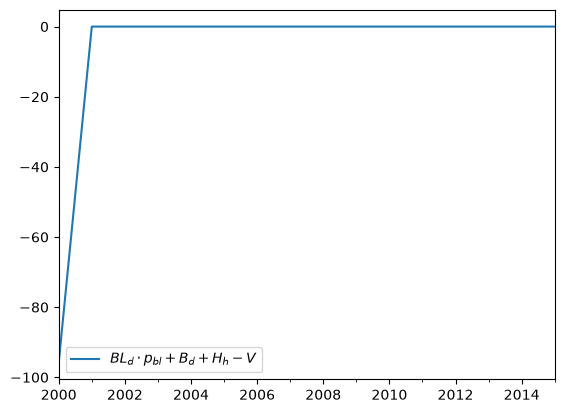

In [ ]:
model.data[bs.sector_zero_expression(Households)].plot()

Or use with `solve_for` to generate equations:

In [ ]:
solve_for(bs.sector_zero_expression(Households), Hh)

Eq(H_h, -BL_d*p_{bl} - B_d + V)

But don't forget that you will get identically zero if there's no `NW` `Variable` defined in the `Sector`:

In [ ]:
bs.sector_zero_expression(Government)

0

In [ ]:
#| hide

assert bs.sector_zero_expression(Households) == Hh + Bd + BLd*Pbl - V
assert bs.sector_zero_expression(Government) == 0
assert bs.sector_zero_expression(CB) == 0
assert bs.sector_zero_expression(Production) == 0

assert solve_for(bs.sector_zero_expression(Households), Hh) == (Hh << V - Bd - BLd*Pbl)

In [ ]:
show_doc(BSmatrix.sector_zero_expressions)

---

[source](https://github.com/slevey087/SFCmodeler/blob/main/SFCmodeler/representations.py#L122){target="_blank" style="float:right; font-size:smaller"}

### BSmatrix.sector_zero_expressions

```python
def sector_zero_expressions()->list[sympy.core.expr.Expr]:
```

*Returns a list of zero expressions for all sectors, but only ones with NW variables defined on the sector.*

In [ ]:
bs.sector_zero_expressions()

[BL_d*p_{bl} + B_d + H_h - V]

Feed this as a key to `ModelResults` in order to check balance sheet identities for all sectors at once.

In [ ]:
#| hide

assert bs.sector_zero_expressions() == [BLd*Pbl + Bd + Hh - V]

# TODO add some toy sectors to make sure this works with multiple

In [ ]:
show_doc(BSmatrix.asset_zero_expressions)

---

[source](https://github.com/slevey087/SFCmodeler/blob/main/SFCmodeler/representations.py#L127){target="_blank" style="float:right; font-size:smaller"}

### BSmatrix.asset_zero_expressions

```python
def asset_zero_expressions()->list[sympy.core.expr.Expr]:
```

*Returns asset supply minus demand for all assets in the balance sheet.*

In [ ]:
bs.asset_zero_expressions()

[-H_h + H_s, -B_d + B_h, -BL_d + BL_h]

In [ ]:
#| hide

assert bs.asset_zero_expressions() == [Hs - Hh, Bh - Bd, BLh - BLd]

Use this as a key to `ModelResults` to check asset demand/supply consistency for all assets at once in your simulation results:

<Axes: >

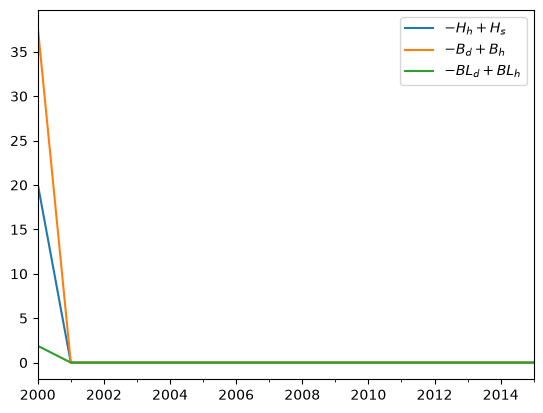

In [ ]:
model.data[bs.asset_zero_expressions()].plot()

In [ ]:
#| export

class Transaction:
  "Represents a row in a Transactions Flow matrix."
  def __init__(self, entries:dict[Sector,sp.Expr | Term]):
    self.entries=dict(entries)

  def __repr__(self):
    return self.zero_expression().__repr__()

  def _repr_latex_(self):
    return self.zero_expression()._repr_latex_()
  
  def __setitem__(self, sector, expression):
    self.entries[sector] = expression
  
  def __getitem__(self, sector):
    return self.entries[sector] if sector in self.entries else sp.S.Zero

  def zero_expression(self) -> sp.Expr:
    "Sums across the transaction (horizontal sum), which should equal zero by identity."
    return sp.Add(*self.entries.values(),evaluate=False)


Create a `Transaction` by supplying a dictionary where the keys are `Sector`s and the values are the expressions for that sector in the transaction:

In [ ]:
Consumption = Transaction({Households:-C, Production:C})
GovernmentExpenditures = Transaction({Government:-G,Production:G})
Income = Transaction({Production:-Y, Households:Y})
CBProfits = Transaction({CB:-Rb(-1)*Bcb(-1), Government:Rb(-1)*Bcb(-1)})
Taxes = Transaction({Households:-T, Government:T})

Note that we've skipped transactions for interest payments, changes in assets, and capital gains -- the matrices below will build these for us. But, let's create one just for illustrative purposes:

In [ ]:
InterestOnBills = Transaction({Households:Rb(-1)*Bh(-1),Government:-Rb(-1)*Bs(-1),CB:Rb(-1)*Bcb(-1)})

In [ ]:
#| hide

# two should suffice

assert Consumption.entries == {Households:-C, Production:C}
assert Consumption[Households] == -C and Consumption[Production] == C

assert InterestOnBills[Households] == Rb(-1)*Bh(-1)
assert InterestOnBills[Government] == -Rb(-1)*Bs(-1)
assert InterestOnBills[CB] == Rb(-1)*Bcb(-1)

# unrelated returns zero
assert Taxes[CB] is sp.S.Zero

Quickly fetch an expression for a sector by indexing:

In [ ]:
CBProfits[Government]

B_{cb}_{-1}*r_b_{-1}

Including uninvolved sectors:

In [ ]:
Consumption[CB]

0

In [ ]:
show_doc(Transaction.zero_expression)

---

[source](https://github.com/slevey087/SFCmodeler/blob/main/SFCmodeler/representations.py#L151){target="_blank" style="float:right; font-size:smaller"}

### Transaction.zero_expression

```python
def zero_expression()->sympy.core.expr.Expr:
```

*Sums across the transaction (horizontal sum), which should equal zero by identity.*

In [ ]:
Consumption.zero_expression()

-C + C

For some transactions this is trivial, but for others it is more useful, e.g.

In [ ]:
InterestOnBills.zero_expression()

B_h_{-1}*r_b_{-1} - B_s_{-1}*r_b_{-1} + B_{cb}_{-1}*r_b_{-1}

In [ ]:
#| hide

assert Consumption.zero_expression() == sp.Add(-C,C,evaluate=False)
assert InterestOnBills.zero_expression() == sp.Add(Bh(-1)*Rb(-1), - Bs(-1)*Rb(-1), + Bcb(-1)*Rb(-1),evaluate=False)

Use this as a key with `ModelResults` to check for horizontal consistency

In [ ]:
model.data[InterestOnBills.zero_expression()]

|      |   $B_{h,-1} \cdot r_{b,-1} - B_{s,-1} \cdot r_{b,-1} + B_{cb,-1} \cdot r_{b,-1}$ |
|:-----|---------------------------------------------------------------------------------:|
| 2000 |                                                                      0           |
| 2001 |                                                                      2.22045e-16 |
| 2002 |                                                                     -2.22045e-16 |
| 2003 |                                                                      0           |
| 2004 |                                                                     -2.22045e-16 |
| 2005 |                                                                      0           |
| 2006 |                                                                      0           |
| 2007 |                                                                      0           |
| 2008 |                                                                      0           |
| 2009 |                                                                      4.44089e-16 |
| 2010 |                                                                      2.22045e-16 |
| 2011 |                                                                     -2.22045e-16 |
| 2012 |                                                                      0           |
| 2013 |                                                                      0           |
| 2014 |                                                                      0           |
| 2015 |                                                                     -2.22045e-16 |

or with `solve_for` to generate equations:

In [ ]:
solve_for(InterestOnBills.zero_expression(),Bs(-1))

Eq(B_s_{-1}, B_h_{-1} + B_{cb}_{-1})

In [ ]:
#| export

class TFmatrix:
  "Class representing the Transactions Flow matrix."
  def __init__(self, sectors, transactions, assets=None):
    self.sectors = sectors
    self.transactions = transactions
    self.assets = assets

    if assets is not None:
      self.interest_transactions = {asset:self.interest_on(asset) for asset in assets}
      self.transactions = self.transactions + list(self.interest_transactions.values())
      self.holding_transactions = {asset:self.change_in_holdings(asset) for asset in assets}
      self.transactions = self.transactions + list(self.holding_transactions.values())

  def interest_on(self, asset):
    return Transaction({
        sector:asset.payout_to(sector) for sector in self.sectors if asset.payout_to(sector) != 0} | {
        asset.issuer:(-asset.payout(asset.total_supply) if asset.payout is not None else sp.S.Zero)
    })

  def change_in_holdings(self, asset):
    "Transaction Flow matrix row for the change in the stock of `asset`: holders negative (use of funds), issuer positive."
    entries = {sector: -d(asset.demands[sector] if (asset.demands is not None and sector in asset.demands) else asset.supplies[sector]) * asset.price for sector in asset.holders()}
    if asset.issuer is not None:
        issued = (d(asset.total_supply) if asset.total_supply is not None
                  else sp.Add(*[d(asset.held(s)) for s in asset.holders()]))
        entries[asset.issuer] = entries.get(asset.issuer, 0) + issued * asset.price
    return Transaction(entries)

  def change_in_sector_holdings(self, sector):
      "Sums the change in asset holding entries for a particular sector."
      return sp.Add(*[transaction[sector] for transaction in self.holding_transactions.values()])
    
  def sector_zero_expression(self, sector:Sector) -> sp.Expr:
     "Returns the sume of a column (income - spending - change in holdings) for specified sector."
     return sp.Add(*[transaction[sector] for transaction in self.transactions])

  def sector_zero_expressions(self) -> list[sp.Expr]:
     "Returns the sume of a column (income - spending - change in holdings) for all sectors."
     return [self.sector_zero_expression(sector) for sector in self.sectors]
    
  def transaction_zero_expressions(self):
      "Return all transaction zero expressions (row sums)."
      return [transaction.zero_expression() for transaction in self.transactions]

In [ ]:
tf = TFmatrix(
    sectors = [Households, Production, Government, CB],
    transactions = [Consumption, GovernmentExpenditures, Income, CBProfits, Taxes],
    assets = [Money, Bills, Bonds]
)

`assets` is optional, but if you put it in, the matrix will generate additional transactions automatically for interest payments and changes in stocks. Then you can use the matrix to generate expressions or equations as follows.

In [ ]:
#| hide 

# TODO add tests for interest_on and change_in_holdings

In [ ]:
show_doc(TFmatrix.sector_zero_expression)

---

[source](https://github.com/slevey087/SFCmodeler/blob/main/SFCmodeler/representations.py#L189){target="_blank" style="float:right; font-size:smaller"}

### TFmatrix.sector_zero_expression

```python
def sector_zero_expression(
    sector:__main__.Sector
)->sympy.core.expr.Expr:
```

*Returns the sume of a column (income - spending - change in holdings) for specified sector.*

In [ ]:
tf.sector_zero_expression(Government)

-G - BL_s_{-1} + B_s - B_s_{-1}*r_b_{-1} - B_s_{-1} + B_{cb}_{-1}*r_b_{-1} + T + p_{bl}*(BL_s - BL_s_{-1})

In [ ]:
#| hide

# TODO test sector_zero_expression

Use this with `solve_for` to generate sector transaction equations:

In [ ]:
solve_for(tf.sector_zero_expression(Government),Bs)

Eq(B_s, G - BL_s*p_{bl} + BL_s_{-1}*p_{bl} + BL_s_{-1} + B_s_{-1}*r_b_{-1} + B_s_{-1} - B_{cb}_{-1}*r_b_{-1} - T)

In [ ]:
show_doc(TFmatrix.sector_zero_expressions)

---

[source](https://github.com/slevey087/SFCmodeler/blob/main/SFCmodeler/representations.py#L193){target="_blank" style="float:right; font-size:smaller"}

### TFmatrix.sector_zero_expressions

```python
def sector_zero_expressions()->list[sympy.core.expr.Expr]:
```

*Returns the sume of a column (income - spending - change in holdings) for all sectors.*

In [ ]:
tf.sector_zero_expressions()

[BL_h_{-1} - B_d + B_d_{-1} + B_h_{-1}*r_b_{-1} - C - H_h + H_h_{-1} - T + Y + p_{bl}*(-BL_d + BL_d_{-1}),
 G + C - Y,
 -G - BL_s_{-1} + B_s - B_s_{-1}*r_b_{-1} - B_s_{-1} + B_{cb}_{-1}*r_b_{-1} + T + p_{bl}*(BL_s - BL_s_{-1}),
 -B_{cb} + B_{cb}_{-1} + H_s - H_s_{-1}]

In [ ]:
#| hide

# TODO tests here

In [ ]:
show_doc(TFmatrix.transaction_zero_expressions)

---

[source](https://github.com/slevey087/SFCmodeler/blob/main/SFCmodeler/representations.py#L203){target="_blank" style="float:right; font-size:smaller"}

### TFmatrix.transaction_zero_expressions

```python
def transaction_zero_expressions():
```

*Return all transaction zero expressions (row sums).*

In [ ]:
tf.transaction_zero_expressions()

[-C + C,
 -G + G,
 -Y + Y,
 -B_{cb}_{-1}*r_b_{-1} + B_{cb}_{-1}*r_b_{-1},
 -T + T,
 0,
 B_h_{-1}*r_b_{-1} - B_s_{-1}*r_b_{-1} + B_{cb}_{-1}*r_b_{-1},
 BL_h_{-1} - BL_s_{-1},
 (-H_h + H_h_{-1}) + (H_s - H_s_{-1}),
 (-B_d + B_d_{-1}) + (B_s - B_s_{-1}) + (-B_{cb} + B_{cb}_{-1}),
 p_{bl}*(-BL_d + BL_d_{-1}) + p_{bl}*(BL_s - BL_s_{-1})]

In [ ]:
#| hide

# TODO tests here

In [ ]:
show_doc(TFmatrix.change_in_sector_holdings)

---

[source](https://github.com/slevey087/SFCmodeler/blob/main/SFCmodeler/representations.py#L185){target="_blank" style="float:right; font-size:smaller"}

### TFmatrix.change_in_sector_holdings

```python
def change_in_sector_holdings(
    sector
):
```

*Sums the change in asset holding entries for a particular sector.*

In [ ]:
tf.change_in_sector_holdings(Government)

B_s - B_s_{-1} + p_{bl}*(BL_s - BL_s_{-1})

In [ ]:
#| hide

assert tf.change_in_sector_holdings(Households) == -Bd + Bd(-1) - Hh + Hh(-1) + Pbl*(-BLd + BLd(-1))
assert tf.change_in_sector_holdings(CB) == -Bcb + Bcb(-1) + Hs - Hs(-1)
assert tf.change_in_sector_holdings(Government) == Bs - Bs(-1) + Pbl*(BLs - BLs(-1))
assert tf.change_in_sector_holdings(Production) is sp.S.Zero

In [ ]:
#| export

class RVmatrix:
    def __init__(self, assets:list[Asset], sectors:list[Sector]):
        self.assets = assets
        self.sectors = sectors
        
        self.entries = {(asset, sector):RVmatrix.gain_expression(asset.demands[sector] if sector in asset.demands else (asset.supplies[sector] if sector in asset.supplies else asset.total_supply), asset.price) for asset in assets for sector in sectors if (sector in asset or asset.issuer == sector)}
        

    def __getitem__(self, key:tuple[Asset,Sector]) -> sp.Expr:
        if key in self.entries: return self.entries[key]
        else: return sp.S.Zero

    def __setitem__(self, key:tuple[Asset,Sector],value:sp.Expr):
        self.entries[key] = value
    
    @staticmethod
    def gain_expression(q_term, p_term):
        return d(p_term) * lag(q_term)

    def sector_expression(self, sector:Sector) -> sp.Expr:
        "Sums all the capital gains terms for a single sector (column sum)."
        return sp.Add(*[self[(asset, sector)] for asset in self.assets if self[(asset, sector)] != 0])

    def asset_expression(self, asset:Asset) ->sp.Expr:
        "Sums all the capital gains terms for a single asset (row sum)."
        return sp.Add(*[self[asset, sector] for sector in self.sectors if self[asset, sector] != 0], evaluate = False)
    

Create a revaluation matrix by specifying the assets and sectors it should contain:

In [ ]:
rv = RVmatrix(
    assets = [Money, Bills, Bonds],
    sectors = [Households, Production, Government, CB]
)

The class will automatically generate expressions for every capital gain term, which you can access like this:

In [ ]:
rv[(Bonds, Households)]

BL_d_{-1}*(p_{bl} - p_{bl}_{-1})

Including ones which don't exist:

In [ ]:
rv[(Production, Money)]

0

In [ ]:
#| hide

assert rv.entries == {
 (Money, Households): 0,
 (Money, CB): 0,
 (Bills, Households): 0,
 (Bills, Government): 0,
 (Bills, CB): 0,
 (Bonds, Households): BLd(-1)*(Pbl - Pbl(-1)),
 (Bonds, Government): BLs(-1)*(Pbl - Pbl(-1))
}

assert rv[(Money, Households)] == 0
assert rv[(Money, CB)] == 0
assert rv[(Bills, Households)] == 0
assert rv[(Bills, Government)] == 0
assert rv[(Bills, CB)] == 0
assert rv[(Bonds, Households)] == BLd(-1)*(Pbl - Pbl(-1))
assert rv[(Bonds, Government)] == BLs(-1)*(Pbl - Pbl(-1))

assert rv[(Production, Money)] == 0 # etc.

In [ ]:
#| hide

rv1 = RVmatrix(
    assets = [],
    sectors = []
)

rv1.entries[(Bonds, Households)] = RVmatrix.gain_expression(BLh,Pbl)
assert rv1[(Bonds, Households)] == BLh(-1)*(Pbl-Pbl(-1))
assert rv1[(Bills, Households)] is sp.S.Zero

In [ ]:
show_doc(RVmatrix.asset_expression)

---

[source](https://github.com/slevey087/SFCmodeler/blob/main/SFCmodeler/representations.py#L231){target="_blank" style="float:right; font-size:smaller"}

### RVmatrix.asset_expression

```python
def asset_expression(
    asset:__main__.Asset
)->sympy.core.expr.Expr:
```

*Sums all the capital gains terms for a single asset (row sum).*

In [ ]:
rv.asset_expression(Bonds)

BL_d_{-1}*(p_{bl} - p_{bl}_{-1}) + BL_s_{-1}*(p_{bl} - p_{bl}_{-1})

In [ ]:
show_doc(RVmatrix.sector_expression)

---

[source](https://github.com/slevey087/SFCmodeler/blob/main/SFCmodeler/representations.py#L227){target="_blank" style="float:right; font-size:smaller"}

### RVmatrix.sector_expression

```python
def sector_expression(
    sector:__main__.Sector
)->sympy.core.expr.Expr:
```

*Sums all the capital gains terms for a single sector (column sum).*

In [ ]:
rv.sector_expression(Households)

BL_d_{-1}*(p_{bl} - p_{bl}_{-1})

In [ ]:
#| hide

assert rv.sector_expression(Households) == BLd(-1)*(Pbl-Pbl(-1))
assert rv.sector_expression(Production) == 0
assert rv.sector_expression(CB) == 0
assert rv.sector_expression(Government) == BLs(-1)*(Pbl-Pbl(-1))

This is the last item needed to generate full change-in-wealth equations:

In [ ]:
show_doc(Sector.wealth_zero_expression)

---

[source](https://github.com/slevey087/SFCmodeler/blob/main/SFCmodeler/representations.py#L21){target="_blank" style="float:right; font-size:smaller"}

### Sector.wealth_zero_expression

```python
def wealth_zero_expression(
    tf:__main__.TFmatrix, rv:__main__.RVmatrix
)->sympy.core.expr.Expr:
```

In [ ]:
Households.wealth_zero_expression(tf, rv)

-BL_d_{-1}*(p_{bl} - p_{bl}_{-1}) - B_d + B_d_{-1} - H_h + H_h_{-1} + V - V_{-1} + p_{bl}*(-BL_d + BL_d_{-1})

In [ ]:
#| hide

# TODO figure out what the hell is going on here
Households.wealth_zero_expression(tf, rv) == (V - V(-1) - (Hh - Hh(-1) + Bd - Bd(-1) + Pbl*(BLd - BLd(-1)) + BLd(-1)*(Pbl - Pbl(-1))))

False